***
# __EINLEITUNG__
Dieses Projekt beschäftigt sich mit dem Datensatz "Road Accident dataset". Er enthält Daten zu Autounfällen, wie unter anderem deren Datierung, verschiedene Umstände wie Lichtverhältnisse und Details zur Unfallstelle und dem Wetter und den Schweregrad des Unfalls klassifiziert nach "Slight", "Serious" und "Fatal".

Ziel des Projekts ist es, deskriptiv zu ermitteln, unter welchen zeitlichen, infrastrukturellen und umweltbedingten Umständen (u. a. Tageszeit, Wochentag, Straßentyp, Ortslage, Licht- und Wetterverhältnisse) Verkehrsunfälle absolut am häufigsten auftreten und welche dieser Merkmale die stärksten statistischen Zusammenhänge mit dem Schweregrad der Unfälle aufweisen.

Um einen ersten Überblick zum Thema zu erhalten wurden die Folgenden Publikationen genutzt: 

- **Vaiyapuri & Gupta (2021):** "Traffic accident severity prediction and cognitive analysis using deep learning"
    - **Fragestellung:** Welche straßen-, umwelt-, fahrer-, fahrzeug- und unfallezogenen Faktoren beeinflussen die Schwere von Verkehrsunfällen am stärksten? (Daten aus Indien, keine Angaben zu Datierung) (https://d1wqtxts1xzle7.cloudfront.net/enriched-references/5e13d0c5-397b-4e36-a2eb-beed1801d0fe.pdf?response-content-disposition=inline%3B+filename%3D%22Traffic_accident_severity_prediction_and.pdf%22%3B+filename*%3DUTF-8%27%27Traffic_accident_severity_prediction_and.pdf&Expires=1795033643&Signature=E4uo6eS3q6adQyYV6CbEAnd9X48Y99QFGDyb7bUAmSqlgns4iTPOg6tJEuEXcolM-EL2YBW05ACTsMYfgjuq4tysSpdfi9jXIAz5jIP1H1cxEI4VNgM1-BKy7E35IZWxGEtp~knO4EwpN5Mia9OieqfNXJH4iHNM6u0YL-mnkFeAFGOl~iIM3905USKUTJtpcs9~HvFpIESdTFgQSl-KlNiEqBEyhebuglzpWnHgRa5fuGsCHc~tTpfJV-koy1xDDEgaEgY47g69YEkWr95FmZMOj--fYsq0K5-OnWmFkEgrpUVm8NvRxrb~OsqdGacXTxaTADKUdCZtYpsAnz9NNQ__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA, 18.11.2026)
    
    - **Relevante Erkenntnisse**: 
        - Einflussreichste Faktoren sind der Fahrzeugtyp, das Alter der verunglückten Person sowie die Anzahl der beteiligten Fahrzeuge. Deutlich geringere statistische Zusammenhänge zeigten hingegen Straßenoberfläche und Wetterbedingungen.

- **Eboli, Forciniti & Mazzulla (2020):** "Factors influencing accident severity: an analysis by road accident type"
    - **Fragestellung:** Welche straßen-, umwelt-, fahrer- und unfallbezogenen Faktoren beeinflussen die Art der Kollision und wie unterscheiden sich diese Einflussfaktoren zwischen leichten Unfällen und schweren/tödlichen Unfällen? (Daten aus Italien, 2016) (https://www.sciencedirect.com/science/article/pii/S2352146520303197, 18.11.2026)

    - **Relevante Erkenntnisse**: 
        - Straßenmerkmale dominieren: Unabhängig von der Unfallschwere haben straßenbezogene Faktoren den größten Einfluss auf das Unfallgeschehen – allen voran der Straßenabschnitt/Kreuzungsbereich, gefolgt vom Straßentyp und der Lage.

        - Unterschiede nach Unfallschwere:

            -  Bei leichten Unfällen spielen Umweltfaktoren (wie Tageszeit, Wochentag und sonniges Wetter) sowie die Ortslage (innerorts) eine signifikante Rolle.

            - Bei schweren/tödlichen Unfällen verliert das Wetter an statistischer Signifikanz; stattdessen werden Fahrbahnbeschaffenheit (nasse/nicht-trockene Fahrbahn erhöht das Risiko für schwere Frontal-/Seitenkollisionen deutlich), Tageszeit (Nachtstunden) und fahrerbezogene Merkmale (geringere Fahrerfahrung) entscheidend.



Aus diesen Publikationen sowie der eigenen Intuition lassen sich die folgenden Hypothesen Formen:
- Allgemein treten Unfälle häufiger vor wenn:
    - der Unfall in einer urbanen Gegend stattgefunden hat
    -  

Zunächst wird ein grober Überblick über den Datensatz gegeben. Dabei werden die enthaltenen Variablen hinsichtlich ihrer Skalenniveaus eingeordnet und kurz beschrieben.

Bevor die eigentliche Analyse beginnt, werden die Dateneinträge genauer untersucht, um mögliche ungültige Werte zu identifizieren und festzustellen, ob bestimmte Variablen für die weitere Analyse nicht relevant sind.
***

***
# __ERSTER BLICK AUF DEN DATENSATZ__

#### <u>Import der zur Datenanalyse benötigten Module</u>

In [1]:
#Import der zur Datenanalyse benötigten Module
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Erstellung des Dataframes aus der CSV Datei
df = pd.read_csv("Road_Accident_Data.csv")

#### <u>Variablen, Skalenniveaus und Beschreibungen</u>


Um einen Überblick über den Datensatz zu erhalten, werden zunächst die enthaltenen Variablen betrachtet. Dazu werden diese den entprechenden Skalenniveaus zugeordnet und kurz beschrieben.

| Variable | Skalenniveau | Beschreibung |
| --- | --- | --- |
| Accident_Index | Nominal | Eindeutige ID des Unfalls |
| Accident_Date | Nominal | Datum, an dem der Unfall stattgefunden hat |
| Month | Nominal | Monat, in dem der Unfall stattgefunden hat (redundant) |
| Day_of_Week | Nominal | Wochentag, an dem der Unfall stattgefunden hat |
| Year | Nominal | Jahr, in dem der Unfall stattgefunden hat (redundant) |
| Junction_Control | Nominal | Art der Verkehrssteuerung am Unfallort |
| Junction_Detail | Nominal | Details zur Unfallstelle |
| Accident_Severity | Ordinal | Schweregrad des Unfalls (Slight/Serious/Fatal)|
| Latitude | Nominal | Breitengrad der Unfallstelle |
| Light_Conditions | Nominal | Lichtverhältnisse während des Unfalls |
| Local_Authority_(District) | Nominal | Lokale Behörde am Unfallort |
| Carriageway_Hazards | Nominal | Art des Hindernis auf der Straße |
| Longitude | Nominal | Längegrad der Unfallstelle |
| Number_of_Casualties | Kardinal | Anzahl der Verletzten |
| Number_of_Vehicles | Kardinal | Anzahl der beteiligten Fahrzeuge |
| Police_Force | Nominal | Zuständige Polizeibehörde |
| Road_Surface_Conditions | Nominal | Zustand der Straße (Nass/Trocken/...) |
| Road_Type | Nominal | Art der Straße |
| Speed_limit | Kardinal | Geschwindikeitsbegrenzung an der Unfallstelle |
| Time | Nominal | Zeit des Unfalls |
| Urban_or_Rural_Area | Nominal | Ländlich/Städtisch gelegen |
| Weather_Conditions | Nominal | Wetterbedingungen zur Zeit des Unfalls |
| Vehicle_Type | Nominal | Art der beteiligten Fahrzeuge |


In [17]:
#Vorgezogene Datenbereinigung: Korrektut der Wochentage

#errors="coerce" wandelt fehlerhafte Datumsangaben in NaT um, dayfirst=False gibt an, dass das Datum im Format Monat/Tag/Jahr vorliegt
df["Accident_Date"] = pd.to_datetime(df["Accident_Date"], dayfirst=False, errors="coerce")

#Gibt Fehlerhafte Tagesangaben aus, die nicht mit dem Wochentag übereinstimmen
fehlerhafte_tage = (df["Day_of_Week"] != df["Accident_Date"].dt.day_name()).sum()
print(f"Vorher: Anzahl Zeilen mit falschem Wochentag: {fehlerhafte_tage}")

#ersetzt die fehlerhaften Tagesangaben durch die korrekten Wochentage
df["Day_of_Week"] = df["Accident_Date"].dt.day_name()

#Gibt Fehlerhafte Tagesangaben aus, die nicht mit dem Wochentag übereinstimmen
fehlerhafte_tage = (df["Day_of_Week"] != df["Accident_Date"].dt.day_name()).sum()
print(f"Nachher: Anzahl Zeilen mit falschem Wochentag: {fehlerhafte_tage}")

Vorher: Anzahl Zeilen mit falschem Wochentag: 0
Nachher: Anzahl Zeilen mit falschem Wochentag: 0


In [26]:
#Transformation: NAN-Werte in "Carriageway_Hazards" "No Hazards" einsetzen
df["Carriageway_Hazards"] = df["Carriageway_Hazards"].fillna("No Hazards")

In [ ]:
#Ergänzung zur Auswertung: Neue Spalte "Full_Hour" aus "Time" ableiten (1 = 1:00 - 1:59 Uhr)

df["Full_Hour"] = df["Time"].str.split(":").str[0]

df.head()

,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Full_Hour
0,200901BS70001,2021-01-01,Jan,Friday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,No Hazards,-0.201349,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car,15
1,200901BS70002,2021-01-05,Jan,Tuesday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,No Hazards,-0.199248,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car,10
2,200901BS70003,2021-01-04,Jan,Monday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,No Hazards,-0.179599,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car,14
3,200901BS70004,2021-01-05,Jan,Tuesday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,No Hazards,-0.203110,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc,8
4,200901BS70005,2021-01-06,Jan,Wednesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,No Hazards,-0.173445,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car,17


#### <u>Informationen über den Datensatz</u>

Ausgabe der ersten fünf und letzten fünf Zeilen des Datensatzes:

In [25]:
#Alle eindeutigen Ausprägungen der Spalten ausgeben

for spalte in df.columns:
    print (f"Name der Spalte: {spalte}")
    if df[spalte].dtype != 'int64' and df[spalte].dtype != 'float64':
        print(df[spalte].unique())

Name der Spalte: Accident_Index
<StringArray>
['200901BS70001', '200901BS70002', '200901BS70003', '200901BS70004',
 '200901BS70005', '200901BS70006', '200901BS70007', '200901BS70008',
 '200901BS70009', '200901BS70010',
 ...
 '201091NM00903', '201091NM00939', '201091NM01053', '201091NM01085',
 '201091NM01190', '201091NM01760', '201091NM01881', '201091NM01935',
 '201091NM01964', '201091NM02142']
Length: 197644, dtype: str
Name der Spalte: Accident_Date
<DatetimeArray>
['2021-01-01 00:00:00', '2021-01-05 00:00:00', '2021-01-04 00:00:00',
 '2021-01-06 00:00:00', '2021-01-08 00:00:00', '2021-01-02 00:00:00',
 '2021-01-07 00:00:00', '2021-01-10 00:00:00', '2021-01-16 00:00:00',
 '2021-01-12 00:00:00',
 ...
 '2022-09-13 00:00:00', '2022-10-31 00:00:00', '2022-11-21 00:00:00',
 '2022-12-02 00:00:00', '2022-12-18 00:00:00', '2022-12-29 00:00:00',
 '2022-12-30 00:00:00', '2022-12-26 00:00:00', '2022-07-25 00:00:00',
 '2022-12-25 00:00:00']
Length: 730, dtype: datetime64[us]
Name der Spalte: Mont

In [18]:
#Ausgabe der obersten fünf Zeilen
df.head()

,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200901BS70001,2021-01-01,Jan,Friday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,NaN,-0.201349,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car
1,200901BS70002,2021-01-05,Jan,Tuesday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,NaN,-0.199248,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car
2,200901BS70003,2021-01-04,Jan,Monday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,NaN,-0.179599,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car
3,200901BS70004,2021-01-05,Jan,Tuesday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,NaN,-0.203110,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc
4,200901BS70005,2021-01-06,Jan,Wednesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,NaN,-0.173445,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car


<br>
Als nächstes werden allgemeine Informationen über den Datensatz untersucht:

In [19]:
#Informationen über den Datensatz ausgeben
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307973 entries, 0 to 307972
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Accident_Index            307973 non-null  str           
 1   Accident_Date             307973 non-null  datetime64[us]
 2   Month                     307973 non-null  str           
 3   Day_of_Week               307973 non-null  str           
 4   Year                      307973 non-null  int64         
 5   Junction_Control          307973 non-null  str           
 6   Junction_Detail           307973 non-null  str           
 7   Accident_Severity         307973 non-null  str           
 8   Latitude                  307973 non-null  float64       
 9   Light_Conditions          307973 non-null  str           
 10  Local_Authority_District  307973 non-null  str           
 11  Carriageway_Hazards       5424 non-null    str           
 12  Longitude    

Der Datensatz hat 23 Spalten und 307973 Zeilen. Die Spaltenbenennung ist intuitiv.

Die Spalten "Carriageway_Hazards", "Road_Surface_Conditions", "Road_Type", "Time" und "Weather_Conditions" enthalten jeweils Null-Werte. 

Im Fall der "Carriageway_Hazards" ist der Grund, dass Pandas Zeilen die mit "None" gefüllt sind (keine Hindernisse vorhanden) als Null interpretiert. Da "None" aber ein Aussagekräftiger Wert ist, haben wir uns dazu entschieden, leere Werte dieser Spalte durch den Wert "No Hazards" zu ersetzen (siehe unten)

In den anderen Spalten gibt es keine Erklärung für leere Werte. Um Auswertungen nicht zu verfälschen, werden diese Werte nicht ersetzt, es wurden allerdings auch nicht die entsprechenden Elemente gelöscht, um ihre anderen Werte in der Auswertung berücksichtigen zu können.

Um ein besseres Verständnis und ein erstes Bild der Werteverteilung im Datensatz zu erhalten wurde im Folgenden eine Auswertung mithilfe von pandas.dataframe.describe() erstellt:

<br>

In [20]:
#Auswertung der Werteverteilung der kardinal skalierten Attribute
pd.set_option("display.max_columns", None)

df.describe(include="all")

,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
count,307973,307973,307973,307973,307973.000000,307973,307973,307973,307973.000000,307973,307973,5424,307973.000000,307973.000000,307973.000000,307973,307656,306439,307973.000000,307956,307973,301916,307973
unique,197644,NaN,12,7,NaN,6,9,3,NaN,5,422,5,NaN,NaN,NaN,51,5,5,NaN,1439,2,8,15
top,2.01E+12,NaN,Nov,Saturday,NaN,Give way or uncontrolled,Not at junction or within 20 metres,Slight,NaN,Daylight,Birmingham,Other object on road,NaN,NaN,NaN,Metropolitan Police,Dry,Single carriageway,NaN,17:00,Urban,Fine no high winds,Car
freq,110304,NaN,29095,50529,NaN,150045,123094,263280,NaN,227286,6165,2243,NaN,NaN,NaN,46789,208967,230612,NaN,2933,198532,244496,239794
mean,NaN,2021-12-23 22:19:39.804722,NaN,NaN,2021.468934,NaN,NaN,NaN,52.487005,NaN,NaN,NaN,-1.368884,1.356882,1.829063,NaN,NaN,NaN,38.866037,NaN,NaN,NaN,NaN
min,NaN,2021-01-01 00:00:00,NaN,NaN,2021.000000,NaN,NaN,NaN,49.914488,NaN,NaN,NaN,-7.516225,1.000000,1.000000,NaN,NaN,NaN,10.000000,NaN,NaN,NaN,NaN
25%,NaN,2021-06-28 00:00:00,NaN,NaN,2021.000000,NaN,NaN,NaN,51.485248,NaN,NaN,NaN,-2.247937,1.000000,1.000000,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN
50%,NaN,2021-12-08 00:00:00,NaN,NaN,2021.000000,NaN,NaN,NaN,52.225943,NaN,NaN,NaN,-1.349258,1.000000,2.000000,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN
75%,NaN,2022-06-25 00:00:00,NaN,NaN,2022.000000,NaN,NaN,NaN,53.415517,NaN,NaN,NaN,-0.206810,1.000000,2.000000,NaN,NaN,NaN,50.000000,NaN,NaN,NaN,NaN
max,NaN,2022-12-31 00:00:00,NaN,NaN,2022.000000,NaN,NaN,NaN,60.598055,NaN,NaN,NaN,1.759398,48.000000,32.000000,NaN,NaN,NaN,70.000000,NaN,NaN,NaN,NaN


Es fällt auf, dass gerade "Number_of_Casualties" und "Number_of_Vehicles" trotz einer geringen Standardabweichung starke Ausreißer nach oben aufweisen. 

Im Fall von "Number_of_Casualties" gab es im arithmetischen Mittel ca. 1.36 Verletzte pro Unfall mit einer Standardabweichung von ca. 0.8 aber einem Minimum, Median und oberem Quartil von 1. Dies deutet darauf hin, dass wenige starke Ausreißer das arithmetische Mittel erhöhen. Diese Vermutung wird auch durch das Maximum von 48 Verletzten unterstützt.

Bei "Number of Vehicles" verhält es sich ähnlich, allerdings nicht ganz so stark. Das Arithmetische Mittel beträgt ca. 1.8 Fahrzeuge mit einer Standardabweichung von ca. 0.7., allerdings beträgt das obere Quartil nur 2 Fahrzeuge, was zusammen mit dem Maximalwert von 32 auf starke Ausreißer hindeutet.


Damit man gut mit dem Datensatz arbeiten kann, lohnt es sich die einzelnen Spalten genauer anzuschauen um zu überprüfen, ob alle Spalten wirklich Informationen enthalten, die für spätere Analysen wichtig sind.

Dazu wird überprüft, wie viele verschiedene Werte die einzelnen Spalten beeinhalten:

In [6]:
df[df["Accident_Severity"] == "Fatal"].describe()

,Accident_Date,Year,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles,Speed_Limit
count,3953,3953.000000,3953.000000,3953.000000,3953.000000,3953.000000,3953.000000
mean,2021-11-14 17:50:59.043764,2021.391854,52.522090,-1.376112,1.804958,1.758158,47.042752
min,2021-01-01 00:00:00,2021.000000,50.099786,-6.419208,1.000000,1.000000,20.000000
25%,2021-05-09 00:00:00,2021.000000,51.511255,-2.328732,1.000000,1.000000,30.000000
50%,2021-10-15 00:00:00,2021.000000,52.206187,-1.311376,1.000000,2.000000,50.000000
75%,2022-05-22 00:00:00,2022.000000,53.397978,-0.174694,2.000000,2.000000,60.000000
max,2022-12-31 00:00:00,2022.000000,60.241195,1.751113,48.000000,16.000000,70.000000
std,NaN,0.488226,1.399279,1.416429,1.683197,0.911965,15.596521


In [7]:
df[df["Accident_Severity"] == "Serious"].describe()

,Accident_Date,Year,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles,Speed_Limit
count,40740,40740.000000,40740.000000,40740.000000,40740.000000,40740.000000,40740.000000
mean,2021-12-19 20:31:08.394698,2021.460898,52.559453,-1.368462,1.455866,1.677933,40.589347
min,2021-01-01 00:00:00,2021.000000,50.021621,-7.516225,1.000000,1.000000,20.000000
25%,2021-06-23 00:00:00,2021.000000,51.490064,-2.260465,1.000000,1.000000,30.000000
50%,2021-12-01 00:00:00,2021.000000,52.327612,-1.326420,1.000000,2.000000,30.000000
75%,2022-06-22 00:00:00,2022.000000,53.464259,-0.213772,2.000000,2.000000,60.000000
max,2022-12-31 00:00:00,2022.000000,60.598055,1.755885,42.000000,19.000000,70.000000
std,NaN,0.498475,1.399263,1.356440,1.008319,0.751332,14.577643


In [8]:
df[df["Accident_Severity"] == "Slight"].describe()

,Accident_Date,Year,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles,Speed_Limit
count,263280,263280.000000,263280.000000,263280.000000,263280.000000,263280.000000,263280.000000
mean,2021-12-25 03:35:00.273473,2021.471335,52.475267,-1.368841,1.334837,1.853513,38.476603
min,2021-01-01 00:00:00,2021.000000,49.914488,-7.504121,1.000000,1.000000,10.000000
25%,2021-06-30 00:00:00,2021.000000,51.483878,-2.245926,1.000000,1.000000,30.000000
50%,2021-12-10 00:00:00,2021.000000,52.210750,-1.353693,1.000000,2.000000,30.000000
75%,2022-06-26 00:00:00,2022.000000,53.410871,-0.206672,1.000000,2.000000,40.000000
max,2022-12-31 00:00:00,2022.000000,60.454772,1.759398,43.000000,32.000000,70.000000
std,NaN,0.499179,1.328152,1.355116,0.757462,0.697442,13.863720


263280 + 40740 + 3953 = 307.973 = Gesamtanzahl Zeilen -> Jeder Datensatz ist abgebildet

-> Bei höherer Gesamtanzahl an Verletzten gibt es eine höhere Wahrscheinlichkeit, dass einer tödlich verletzt wird
    -> Auch Standardabweichung ist höher, je schwerer der Unfall (Durchschnitt nah an 1 (minimum), also wenig Platz nach unten -> hohe Standardabweichung deutet auf starke Abweichung nach oben hin.)

-> Anzahl Fahrzeuge scheint nicht zu korellieren (am niedrigsten bei ernsten (mittleren) Verletzungen)
    -> Standardabweichng steit mit "Severity", aber nicht signifikant

-> Speed Limit scheint zu korellieren, je schwerer die Verletzung, desto höher der Durchschnitt, Standardabweichung und Median der Geschwindigkwitsbegrenzung

In [9]:
df.groupby("Speed_Limit")["Number_of_Vehicles"].mean()

Speed_Limit
10    1.000000
15    2.000000
20    1.603311
30    1.788877
40    1.954776
50    1.985674
60    1.787490
70    2.089393
Name: Number_of_Vehicles, dtype: float64

In [10]:
df.groupby("Speed_Limit")["Number_of_Casualties"].mean()

Speed_Limit
10    1.333333
15    1.500000
20    1.190066
30    1.276835
40    1.450253
50    1.508488
60    1.524837
70    1.566676
Name: Number_of_Casualties, dtype: float64

Mit höherer Geschwindigkeit scheinen durchschnittlich auch mehr Fahrzeuge in einen Unfall involviert zu sein. Die Anzahl der Verletzten korelliert schwächer, wird allgemein auch höher mit höherem Speed-Limit

In [11]:
pd.crosstab(df["Urban_or_Rural_Area"], df["Accident_Severity"], normalize="index") * 100

Accident_Severity,Fatal,Serious,Slight
Urban_or_Rural_Area,,,
Rural,2.146362,15.741815,82.111823
Urban,0.807930,11.842927,87.349143


In [12]:
#Speichern aller Spalten in eine Liste über die später iteriert wird
spalten = df.columns.to_numpy()

#Interation über alle Spalten um die Anzahl unterschiedlicher Werte auszugeben
for spalte in spalten:
    print(f"• {spalte} hat {df[spalte].nunique()} unterschiedliche Werte")

• Accident_Index hat 197644 unterschiedliche Werte
• Accident_Date hat 730 unterschiedliche Werte
• Month hat 12 unterschiedliche Werte
• Day_of_Week hat 7 unterschiedliche Werte
• Year hat 2 unterschiedliche Werte
• Junction_Control hat 6 unterschiedliche Werte
• Junction_Detail hat 9 unterschiedliche Werte
• Accident_Severity hat 3 unterschiedliche Werte
• Latitude hat 264362 unterschiedliche Werte
• Light_Conditions hat 5 unterschiedliche Werte
• Local_Authority_District hat 422 unterschiedliche Werte
• Carriageway_Hazards hat 5 unterschiedliche Werte
• Longitude hat 269856 unterschiedliche Werte
• Number_of_Casualties hat 28 unterschiedliche Werte
• Number_of_Vehicles hat 17 unterschiedliche Werte
• Police_Force hat 51 unterschiedliche Werte
• Road_Surface_Conditions hat 5 unterschiedliche Werte
• Road_Type hat 5 unterschiedliche Werte
• Speed_Limit hat 8 unterschiedliche Werte
• Time hat 1439 unterschiedliche Werte
• Urban_or_Rural_Area hat 2 unterschiedliche Werte
• Weather_Condi

<Axes: xlabel='Number_of_Casualties', ylabel='Accident_Severity'>

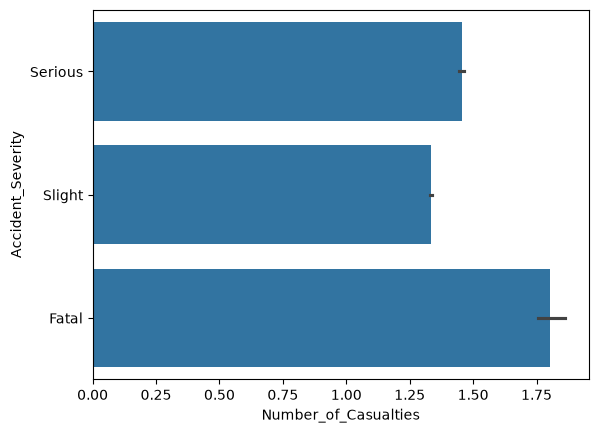

In [13]:
#Erstellung eines Pair-Grids für den Datensatz
sns.barplot(x = "Number_of_Casualties", y = "Accident_Severity", data= df, orient = "h")

KeyError: 'Speed_limit'

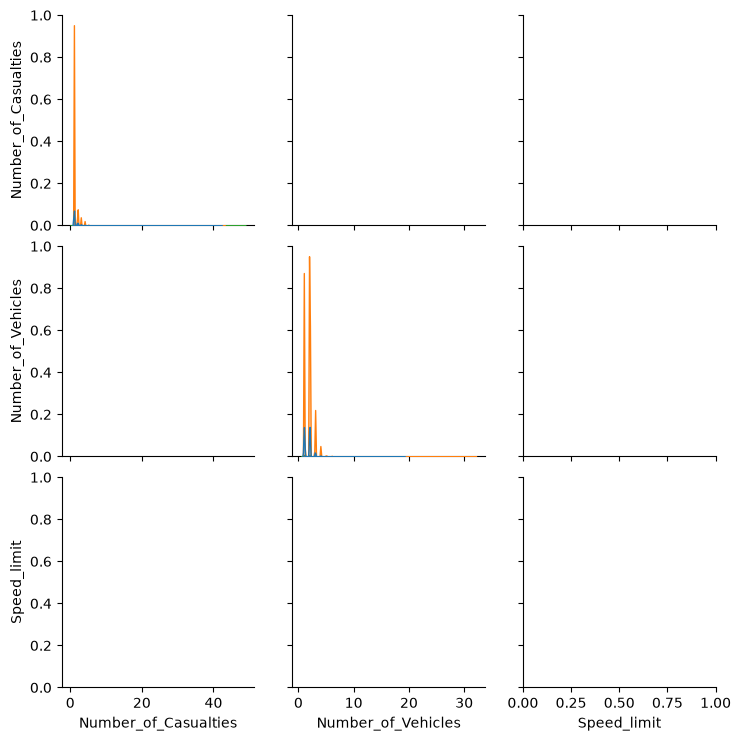

In [14]:
# 2. Sinnvolle numerische Spalten auswählen
cols = ["Number_of_Casualties", "Number_of_Vehicles", "Speed_limit"]

g = sns.pairplot(
    df,
    vars=cols,
    hue="Accident_Severity",
    plot_kws={"alpha": 0.5},  # Transparenz gegen Überlagerung
)
plt.show()

TypeError: The x variable is categorical, but one of ['numeric', 'datetime'] is required

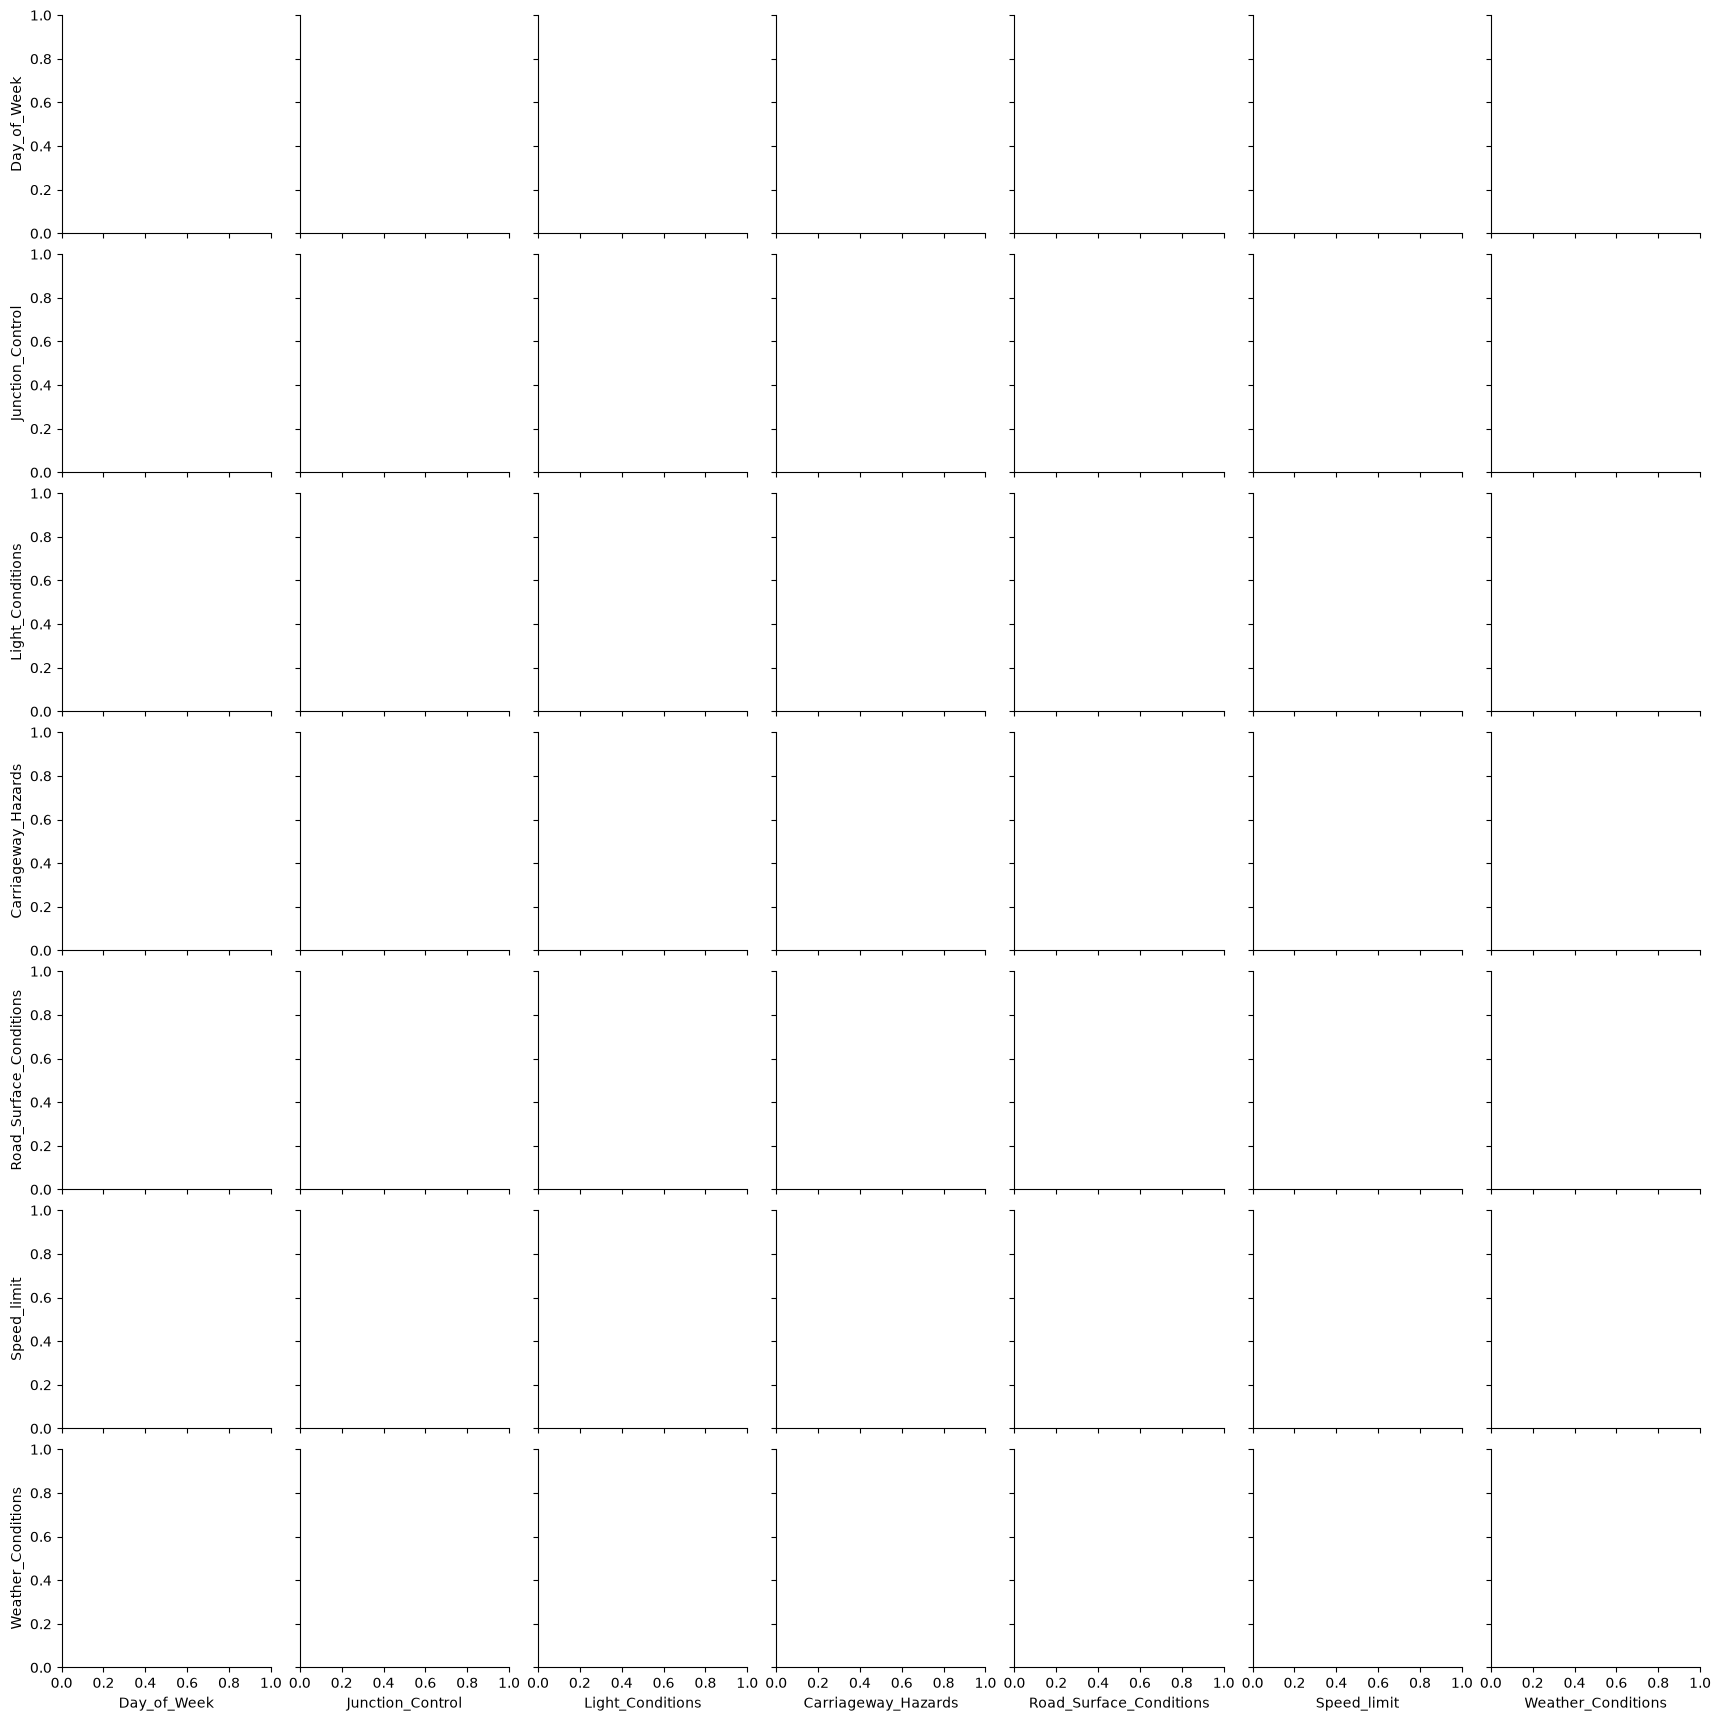

In [ ]:

cols = ["Day_of_Week", "Junction_Control", "Light_Conditions", "Carriageway_Hazards", "Road_Surface_Conditions", "Speed_limit", "Weather_Conditions"]

g = sns.pairplot(
    df,
    vars=cols,
    hue="Accident_Severity",
    plot_kws={"alpha": 0.5},  # Transparenz gegen Überlagerung
)
plt.show()